## Something in the Way: Deep Learning for Crater Detection and Crater-Aware Route Planning on Mars
CSC 383 Final Project Notebook File\
Enes Demirel\
Instructor: Vincent Kurtz

Since the dawn of humanity, people have been asking the same question: *"What is up there?"* In 2026, we do have some answers to this question; however, the big picture remains unanswered. As the most habitable planet in our solar system after Earth, Mars has long attracted humanity. Unfortunately, we are not yet able to send humans there, so we need to do our exploration with rovers. Since it takes approximately 4 to 22 minutes for a signal to reach Mars, steering a rover in real time is not feasible. Therefore, rovers need to learn how to drive themselves autonomously. For a rover to drive autonomously, it is very important to be able to identify dangers on its own, such as craters.

In this project, we are going to try to answer two questions:

1. **What type of model would be best for identifying craters from satellite images of Mars?**
   - a) A model trained from scratch (**U-Net**)
   - b) A fine-tuned model (**Faster R-CNN**)
   - c) A foundation model (**DINOv3**)

Note: We are also going to use a a basic MLP and a basic CNN to have some baseline scores.



2. **How well would two different rovers plan their paths using the best model (Faster R-CNN), and do the craters it misses matter?:**
   - a) **Rover 1:** A rover that plans its whole path from the start with using A*
   - b) **Rover2:** A rover that uses a small neural network to predict the best move at each step from what it sees around it.


Note: The training result sections are not run here. They use saved results from runs in another notebook. The training results also show the test results, but that does not mean the training code computes the test results. The cells after the training sections show how the test is coded.

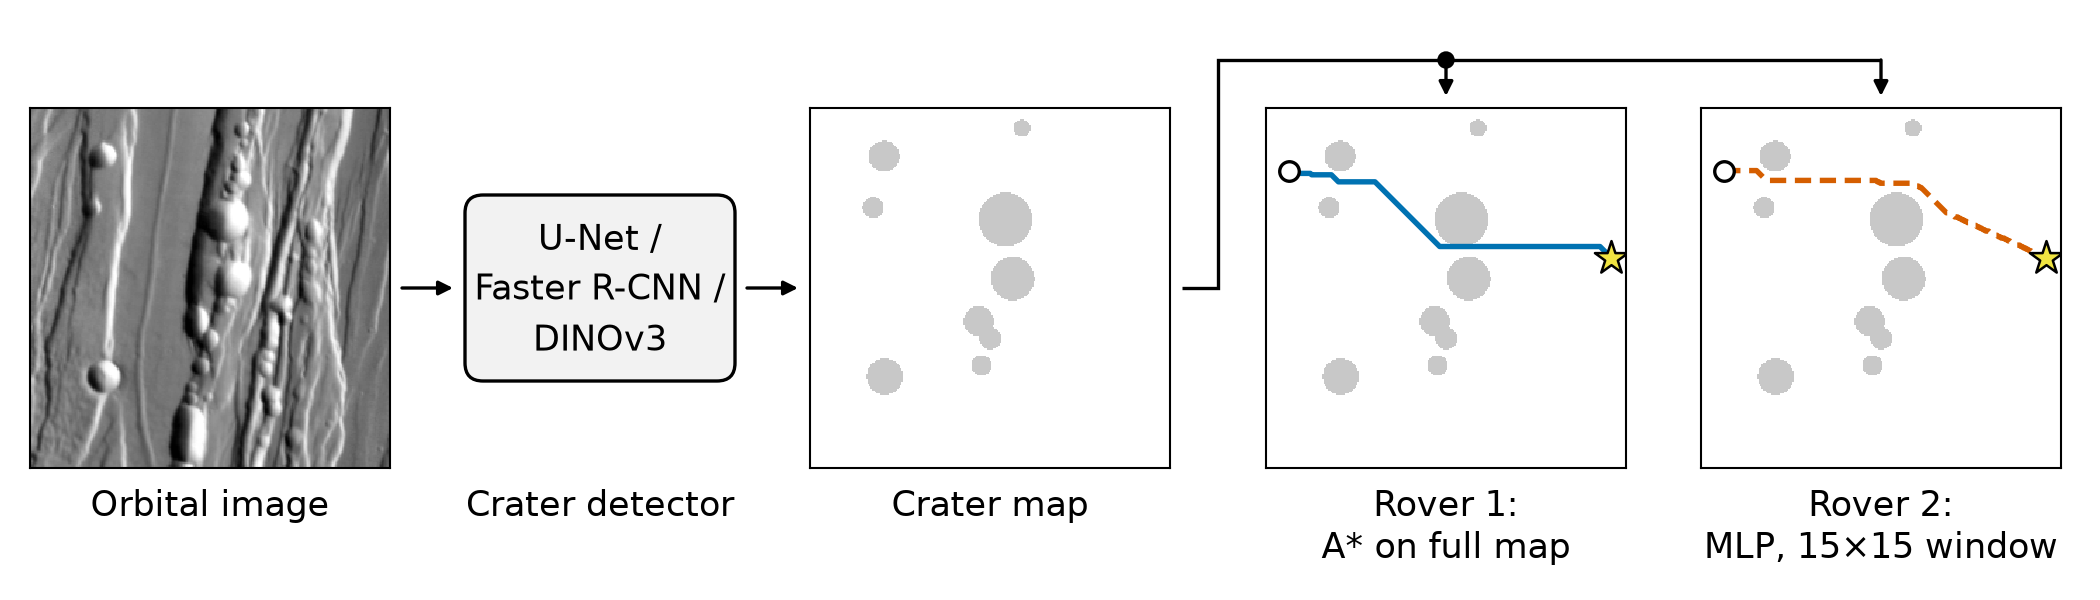

## Imports

**Basic machine learning essentials:** `numpy`, `matplotlib`, `PIL`, `tqdm`, `scikit-learn` (`train_test_split`), and `torch` (`nn`, `F`, `Dataset`, `DataLoader`, `TensorDataset`), `pandas`

**Python standard library:**
- `json`: reads the crater labels and saves the results.
- `random`: sets a fixed seed so the results can be repeated.
- `time`: measures how long each epoch takes.
- `pathlib`: builds the file paths to the images and saved models.

**Project-specific:**
- `heapq`: priority queue for the A* search (Rover 1).
- `Rectangle`: draws crater boxes on images.
- `scipy.ndimage`: finds connected crater blobs in a mask so each blob becomes one box.
- `fasterrcnn_resnet50_fpn`, `FastRCNNPredictor`: the pretrained Faster R-CNN and its new 2-class head (crater / background).
- `box_iou`: overlap between two boxes, used to match predicted craters with true craters.
- `AutoModel` (Hugging Face `transformers`): loads the pretrained DINOv3 backbone.

In [52]:
import json
import random
import time
import heapq
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from scipy import ndimage
from sklearn.model_selection import train_test_split
from tqdm import tqdm
import pandas as pd

import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, TensorDataset

from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.ops import box_iou

from transformers import AutoModel

## Fixed seeds so the results can be repeated, and checking if either "GPU" or "MPS" (Apple) is available for torch.

In [5]:
torch.manual_seed(0)
random.seed(0)

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"
print("Using device:", device)

Using device: cuda


## Data

**Where the dataset comes from:** The dataset is from the 2022 GeoAI Martian Challenge by the ASU CICI Lab (Hsu et al., 2021). the crater labels come from the Robbins and Hynek (2012) crater catalog. It can be downloaded from https://cici.lab.asu.edu/martian/.

**Each image:**
- a 256 × 256 grayscale image
- its labels are stored in `dataset/gt_public.json` as a list of boxes, one per crater, in the format `[x, y, width, height]`

**Cleaning:** The raw data had images with no labels (the test data). We removed them because they can't be used for training or scoring a model. We have 51,838 images left.

In [6]:
# Import the json file with labels in it.
data = json.loads(Path('dataset/gt_public.json').read_text())

assert isinstance(data, dict)
assert len(data) == 51838

In [19]:
# Delete images without any labels
images_path = Path('dataset/images')
deleted = 0
for path in images_path.rglob('*'):
    if path.is_file():
        if path.name[0:6] not in data.keys():
            path.unlink(missing_ok=True)
            deleted += 1
            
print(f"Deleted: 50837 images") # I am using a hardcoded number here because it currently shows 0. This number is the exact number of images that were deleted.
assert sum(1 for item in images_path.iterdir() if item.is_file()) == 51838

Deleted: 50837 images


## Train / validation / test split

We use an 80/10/10 rule for the training, validation and test split.

- **Train:** fits the model.
- **Validation:** picks the best epoch and the best cutoff.
- **Test:** used at the end to test the models on images they have never seen.

Total number of images: **51,838**

- a) Training: **41,470** (80%)
- b) Validation: **5,184** (10%)
- c) Test: **5,184** (10%)

In [20]:
images_path = Path("dataset/images")
data = json.loads(Path("dataset/gt_public.json").read_text())

image_ids = list(data.keys())
train_ids, rest_ids = train_test_split(image_ids, test_size=0.2, random_state=0)
val_ids, test_ids = train_test_split(rest_ids, test_size=0.5, random_state=0)

print(f"Train: {len(train_ids)}, Val: {len(val_ids)}, Test: {len(test_ids)}")

Train: 41470, Val: 5184, Test: 5184


## Crater masks

Every model except Faster R-CNN predicts crater / no crater for each pixel. Therefore, they need a mask as the label, not as boxes.

`make_mask` draws each labeled box as a filled circle (craters are round), with 1 = crater and 0 = ground.
Below: one training image with its boxes, and the mask made from them.

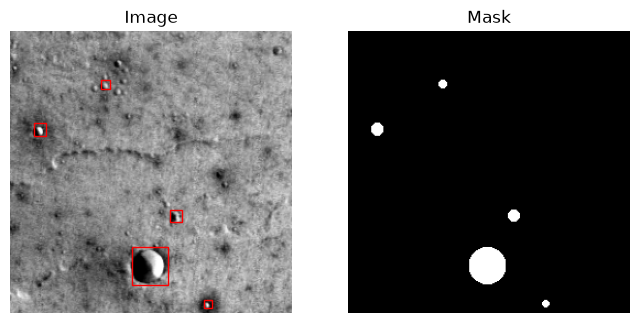

In [44]:
def make_mask(boxes):
    mask = np.zeros((256, 256), dtype=np.uint8)
    yy, xx = np.mgrid[0:256, 0:256]

    for x, y, w, h in boxes:
        cx = x + w / 2
        cy = y + h / 2
        r = max(w, h) / 2
        inside = (xx + 0.5 - cx) ** 2 + (yy + 0.5 - cy) ** 2 <= r ** 2
        mask[inside] = 1

    return mask


image_id = train_ids[2]
image = plt.imread(images_path / f"{image_id}.png")
mask = make_mask(data[image_id])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4))

ax1.imshow(image, cmap="gray")
for x, y, w, h in data[image_id]:
    ax1.add_patch(Rectangle((x, y), w, h, fill=False, edgecolor="red", linewidth=1))
ax1.set_title("Image")
ax1.axis("off")

ax2.imshow(mask, cmap="gray")
ax2.set_title("Mask")
ax2.axis("off")

plt.show()

**Test:** one 20×20 box at (10, 10) should become a circle with center (20, 20) and radius 10. No boxes should give an empty mask.

- Box: top-left corner at x = 10, y = 10; 20 pixels wide and 20 pixels tall
- Expected center: (10 + 20/2, 10 + 20/2) = **(20, 20)**
- Expected radius: 20/2 = **10**
- Expected approximate area = **316**

In [45]:
# Test: one 20x20 box at (10, 10) -> circle with center (20, 20) and radius 10
mask = make_mask([(10, 10, 20, 20)])

assert mask.shape == (256, 256)
assert mask[20, 20] == 1                      # center is crater
assert mask[10, 10] == 0                      # box corner is outside the circle
assert mask[100, 100] == 0                    # far away is ground
assert abs(mask.sum() - 3.14 * 10**2) < 15    # area close to pi * r^2
assert make_mask([]).sum() == 0               # no boxes -> empty mask

print("make_mask tests passed")

make_mask tests passed


## Dataset and loaders

`CraterDataset` is used by the three mask models (MLP, CNN and U-Net). Faster R-CNN and DINOv3 need different inputs, so they get their own dataset classes later.

It gives one (image, mask) pair at a time:
- the image is loaded as grayscale and scaled to 0–1
- the mask is made with `make_mask` from that image's boxes

Both come out with shape (1, 256, 256): single channel and 256x256 pixels.

The loaders give batches of 16, a common default for full 256x256 images that fits in easily in GPU memory.

In [47]:
class CraterDataset(Dataset):
    def __init__(self, image_ids):
        self.image_ids = image_ids

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, i):
        image_id = self.image_ids[i]

        image = Image.open(images_path / f"{image_id}.png").convert("L")
        image = torch.tensor(np.array(image), dtype=torch.float32) / 255.0
        image = image.unsqueeze(0)

        mask = make_mask(data[image_id])
        mask = torch.tensor(mask, dtype=torch.float32).unsqueeze(0)

        return image, mask


train_set = CraterDataset(train_ids)
val_set = CraterDataset(val_ids)
test_set = CraterDataset(test_ids)

train_loader = DataLoader(train_set, batch_size=16, shuffle=True)
val_loader = DataLoader(val_set, batch_size=16, shuffle=False)
test_loader = DataLoader(test_set, batch_size=16, shuffle=False)

images, masks = next(iter(train_loader))
print(images.shape)
print(masks.shape)

torch.Size([16, 1, 256, 256])
torch.Size([16, 1, 256, 256])


## Scoring Functions

We use two different scoring method:
- **Pixel IoU** (only for the mask models): overlap pixels ÷ union pixels between the predicted mask and the true mask, summed over all images.
- **Per-crater precision, recall and F1** (for every model): this is what matters for the rover, and it's the only score that can compare all models together.

Functions:
- `get_true_boxes`: turns the (x, y, w, h) labels into (x1, y1, x2, y2) boxes.
- `count_matches`: a predicted box finds a true crater if their box IoU is at least 0.5.
- `mask_to_boxes`: For making each connected blob in the mask models to become a one box
- `get_scores`: compute precision, recall and F1 from the counts, over all images.

In [48]:
def get_true_boxes(image_id):
    boxes = [[x, y, x + w, y + h] for x, y, w, h in data[image_id] if w > 0 and h > 0]
    return torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4)


def count_matches(pred_boxes, true_boxes, iou_threshold=0.5):
    if len(pred_boxes) == 0 or len(true_boxes) == 0:
        return 0

    ious = box_iou(pred_boxes, true_boxes)
    matches = 0
    for i in range(len(pred_boxes)):
        j = ious[i].argmax()
        if ious[i, j] >= iou_threshold:
            matches += 1
            ious[:, j] = -1  # this real crater is taken
    return matches


def mask_to_boxes(pred_mask):
    labeled, n = ndimage.label(pred_mask)
    boxes = []
    for ys, xs in ndimage.find_objects(labeled):
        boxes.append([xs.start, ys.start, xs.stop, ys.stop])
    return torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4)


def get_scores(tp, n_pred, n_true):
    precision = tp / n_pred if n_pred > 0 else 0.0
    recall = tp / n_true
    f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0.0
    return precision, recall, f1

## Baselines: MLP and CNN


Two simple models for us to see how much the stronger models below improves. Both take a (batch, 1, 256, 256) image and output one crater score per pixel, shape (batch, 1, 256, 256).

- **MLP**: 525,568 parameters
- **CNN**: 166,593 parameters

In [49]:
class PatchMLP(nn.Module):
    def __init__(self, patch=16):
        super().__init__()
        self.patch = patch
        self.mlp = nn.Sequential(
            nn.Linear(patch * patch, 512),
            nn.ReLU(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, patch * patch),
        )

    def forward(self, x):
        b, p = x.shape[0], self.patch
        n = 256 // p

        # cut each image into 16 x 16 patches, flatten each patch
        x = x.view(b, n, p, n, p).permute(0, 1, 3, 2, 4).reshape(b * n * n, p * p)
        x = self.mlp(x)
        # put the patches back together into a 256 x 256 map
        x = x.view(b, n, n, p, p).permute(0, 1, 3, 2, 4).reshape(b, 1, 256, 256)
        return x


def conv_block(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
        nn.ReLU(),
    )


class PlainCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            conv_block(1, 32),    # (32, 256, 256)
            conv_block(32, 64),   # (64, 256, 256)
            conv_block(64, 64),   # (64, 256, 256)
            conv_block(64, 32),   # (32, 256, 256)
            nn.Conv2d(32, 1, kernel_size=1),  # (1, 256, 256)
        )

    def forward(self, x):
        return self.layers(x)

## Baseline Results

The code for the baselines is not shown to avoid crowding this file. These models are only meant to show how much we can improve.

In [54]:
# Validation and test results of the two baselines, read from their saved files
rows = []
for name, folder in [("MLP", "src/mlp/01-baseline"), ("CNN", "src/cnn/01-baseline")]:
    history = json.loads(Path(folder, "history.json").read_text())
    test = json.loads(Path(folder, "test_scores.json").read_text())

    best_epoch = history["val_iou"].index(max(history["val_iou"]))   # epoch with the highest val IoU
    rows.append({
        "Model": name,
        "Best epoch": best_epoch + 1,
        "Cutoff": test["cutoff"],
        "Val IoU": history["val_iou"][best_epoch],
        "Test IoU": test["pixel_iou_0.5"],
        "Test precision": test["precision"],
        "Test recall": test["recall"],
        "Test F1": test["f1"],
    })

pd.DataFrame(rows).set_index("Model").round(3)

,Best epoch,Cutoff,Val IoU,Test IoU,Test precision,Test recall,Test F1
Model,,,,,,,
MLP,6,0.5,0.181,0.176,0.067,0.316,0.110
CNN,7,0.5,0.221,0.215,0.031,0.634,0.059


**Baseline results.** As expected, both baselines are very weak.
- The CNN has a better pixel IoU than the MLP (0.22 vs 0.18), but a worse per-crater F1 (0.06 vs 0.11).
- The MLP only sees one 16×16 patch at a time, and the CNN only a 17×17 area, so neither can see a whole crater.

This is why the next model, U-Net will be a improvement. Each pixel will be able to see a much larger area.

## Advanced Model 1: U-Net (Trained from scratch)


U-Net works with two half:

- **Shrinking half:** convolutional block with max pooling. 256x256 image becomes 32x32. Each pooling halves the size. Therefore, deeper leayers can see much larger area of the image, which is enough to see a whole crater. This is the biggest improvement from the baselines.
- **Growing half:** transposed convolutions bring it back up to 256×256. Shrinking an image and growing it back makes the model forget some details. Therefore, we use a skip connection to bring fine details back in.

- **Input:** (batch, 1, 256, 256) grayscale image
- **Output:** (batch, 1, 256, 256) crater scores (logits), one per pixel
- **Parameters:** 1,925,025


In [57]:
def conv_block(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
        nn.ReLU(),
    )


class UNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.pool = nn.MaxPool2d(2)

        # shrinking half
        self.down1 = conv_block(1, 32)      # (32, 256, 256)
        self.down2 = conv_block(32, 64)     # (64, 128, 128)
        self.down3 = conv_block(64, 128)    # (128, 64, 64)
        self.bottom = conv_block(128, 256)  # (256, 32, 32)

        # growing half
        self.up3 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)  # (128, 64, 64)
        self.conv3 = conv_block(256, 128)
        self.up2 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)   # (64, 128, 128)
        self.conv2 = conv_block(128, 64)
        self.up1 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)    # (32, 256, 256)
        self.conv1 = conv_block(64, 32)

        self.out = nn.Conv2d(32, 1, kernel_size=1)  # (1, 256, 256)

    def forward(self, x):
        d1 = self.down1(x)
        d2 = self.down2(self.pool(d1))
        d3 = self.down3(self.pool(d2))
        b = self.bottom(self.pool(d3))

        u3 = self.conv3(torch.cat([self.up3(b), d3], dim=1))
        u2 = self.conv2(torch.cat([self.up2(u3), d2], dim=1))
        u1 = self.conv1(torch.cat([self.up1(u2), d1], dim=1))
        return self.out(u1)

model = UNet().to(device)
print(sum(p.numel() for p in model.parameters()))

# quick check: one batch in, output should be the same shape as the masks
with torch.no_grad():
    out = model(images.to(device))
print(out.shape)

1925025
torch.Size([16, 1, 256, 256])


## Training the U-Net

- **Loss:** `BCEWithLogitsLoss` with `pos_weight=10`. The weighted version is for avoiding the class imbalance problem since only 2% of the pixels are craters in each image.
- **Optimizer:** Adam, learning rate 0.001, the default.
- **Cosine schedule:** the learning rate goes smoothly from 0.001 down to 0 over 15 epochs.
- **15 epochs**, batch size 16.
- **Cutoff tuning:** For each pixel, the model outputs a probability. The cutoff decides which pixels count as a crater. After each epoch we try 0.5, 0.6, 0.7, 0.8 and 0.9 on validation and keep the best.

Note: The model is saved only when the validation IoU is the best so far.

In [60]:
run_name = "02-cosine-lr"
# Here we use a new folder, /src-submit. The training that was already run saved its output to /src, 
# so the code that reads the logs uses /src.run_dir = Path("src-submit/unet") / run_name
run_dir.mkdir(parents=True, exist_ok=True)

model = UNet().to(device)
loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([10.0], device=device))
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

epochs = 15
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

In [61]:
cutoffs = [0.5, 0.6, 0.7, 0.8, 0.9]


def evaluate(model, loader):
    model.eval()
    total_loss, n = 0.0, 0
    intersection = {c: 0 for c in cutoffs}
    union = {c: 0 for c in cutoffs}

    with torch.no_grad():
        for images, masks in loader:
            images, masks = images.to(device), masks.to(device)

            outputs = model(images)
            total_loss += loss_fn(outputs, masks).item() * len(images)
            n += len(images)

            probs = torch.sigmoid(outputs)
            for c in cutoffs:
                preds = (probs > c).float()
                intersection[c] += (preds * masks).sum().item()
                union[c] += ((preds + masks) > 0).sum().item()

    ious = {c: intersection[c] / union[c] for c in cutoffs}
    best_cutoff = max(ious, key=ious.get)
    return total_loss / n, ious[best_cutoff], best_cutoff

In [ ]:
history = {"train_loss": [], "val_loss": [], "val_iou": [], "best_cutoff": [], "lr": []}
best_iou = 0.0

for epoch in range(epochs):
    model.train()
    running_loss, n = 0.0, 0
    start = time.time()

    for images, masks in progress:
        images, masks = images.to(device), masks.to(device)

        outputs = model(images)
        loss = loss_fn(outputs, masks)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * len(images)
        n += len(images)
        progress.set_postfix(loss=f"{running_loss / n:.4f}")

    train_loss = running_loss / n
    val_loss, val_iou, cutoff = evaluate(model, val_loader)
    lr = optimizer.param_groups[0]["lr"]
    scheduler.step()

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_iou"].append(val_iou)
    history["best_cutoff"].append(cutoff)
    history["lr"].append(lr)
    (run_dir / "history.json").write_text(json.dumps(history))

    saved = ""
    if val_iou > best_iou:
        best_iou = val_iou
        torch.save(model.state_dict(), run_dir / "unet.pt")
        saved = " (saved)"

    print(f"Epoch {epoch + 1}: train loss {train_loss:.4f} | val loss {val_loss:.4f}, "
          f"val IoU {val_iou:.4f} at cutoff {cutoff} | lr {lr:.6f} | {time.time() - start:.0f}s{saved}")

## U-Net Results:

The code above does not have any output cell because the results will be shown below from the saved logs.

In [69]:
# U-Net results, read from its saved files
folder = Path("src/unet/02-cosine-lr")
history = json.loads((folder / "history.json").read_text())
val_craters = json.loads((folder / "crater_scores.json").read_text())   # val precision/recall/F1 per cutoff
test = json.loads((folder / "test_scores.json").read_text())

best_epoch = history["val_iou"].index(max(history["val_iou"]))   # epoch with the highest val IoU
cutoff = str(test["cutoff"])                                      # crater cutoff chosen on validation (0.9)

rows = [
    {"Set": "Validation",
     "Pixel IoU": history["val_iou"][best_epoch],
     "Precision": val_craters[cutoff]["precision"],
     "Recall": val_craters[cutoff]["recall"],
     "F1": val_craters[cutoff]["f1"]},
    {"Set": "Test",
     "Pixel IoU": test["pixel_iou_0.8"],
     "Precision": test["precision"],
     "Recall": test["recall"],
     "F1": test["f1"]},
]

print(f"Best epoch: {best_epoch + 1} of {len(history['val_iou'])}, crater cutoff: {cutoff}")
pd.DataFrame(rows).set_index("Set").round(4)

Best epoch: 10 of 15, crater cutoff: 0.9


,Pixel IoU,Precision,Recall,F1
Set,,,,
Validation,0.5188,0.4980,0.6996,0.5818
Test,0.5115,0.4811,0.7029,0.5712


<img src="attachment:c5e93dd4-6aa7-43de-a7a9-f93ecae146ec.png" width="1000">
<img src="attachment:880614c4-72e8-492b-966f-903a5e5d92f4.png" width="500">

## U-Net Results:

- **Overfit:** We can see that after around epoch 10, even though train loss continues to go down, the validation loss starts increasing. This is a sign of overfitting. Therefore, keeping only the best epoch protected us against saving a model with higher validation loss.

- **Crater Cutoff:** 0.9. A higher cutoff keeps only pixels where the model is very sure about it, which removes most of the false-alarm blobs.

- **Test F1 0.57 vs validation F1 0.58:** Almost the same, so the cutoff choice wasn't arbitrary on the validation set.

- **Better than the baselines:** F1 0.57 vs 0.11 (MLP) and 0.06 (CNN). As mentioned above, seeing a larger area makes a difference.

- **Weakness:** Recall is 0.70, so it still misses 30% of the craters, while precision being 0.48 means half of the predictred craters are false alarms.

## Advanced Model 2: Faster R-CNN (fine-tuned)

> **Note:** Faster R-CNN predicts boxes directly, not masks. Therefore, it needs its own dataset class.

- **Channel fix:** The model was pretrained on color images, so it expects 3 channels. We copy our grayscale images into 3 channels.
- **Boxes as (x1, y1, x2, y2):** Unlike the other models, torchvision expects this format instead of (x, y, w, h), so we convert them. Boxes with zero width or height are ignored.
- **New labels (0, 1):** 1 means crater, 0 means background.
- **`collate_fn`:** Since each image has a different number of craters, we cannot stack the targets into one tensor. Instead, we keep them as a list.

### Model

Faster R-CNN with a ResNet-50 + FPN backbone, pretrained on COCO. We fine-tune it as follows:

- a) The pretrained box classifier is replaced with a new one for only 2 classes.
- b) By default, torchvision resizes each image so its short side is 800 pixels. However, for faster training and less memory usage, we keep them at 256×256.
- c) Parameters: **41,299,161**

> **Note:** Since this model is much bigger (41M parameters), we use a batch size of 8 instead of 16.

At the end, we check whether the converted boxes still sit on the craters.

In [72]:
class CraterDetectionDataset(Dataset):
    def __init__(self, image_ids):
        self.image_ids = image_ids

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, i):
        image_id = self.image_ids[i]

        image = Image.open(images_path / f"{image_id}.png").convert("RGB")
        image = torch.tensor(np.array(image), dtype=torch.float32).permute(2, 0, 1) / 255.0

        boxes = [[x, y, x + w, y + h] for x, y, w, h in data[image_id] if w > 0 and h > 0]
        boxes = torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4)
        labels = torch.ones(len(boxes), dtype=torch.int64)

        return image, {"boxes": boxes, "labels": labels}

8 torch.Size([3, 256, 256])
{'boxes': tensor([[234., 166., 242., 174.],
        [ 39., 155.,  48., 165.],
        [195.,  96., 204., 106.],
        [229., 246., 237., 254.],
        [190., 232., 200., 242.]]), 'labels': tensor([1, 1, 1, 1, 1])}


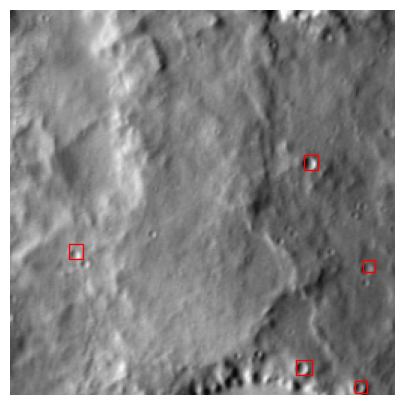

In [78]:
def collate_fn(batch):
    return tuple(zip(*batch))


train_set = CraterDetectionDataset(train_ids)
val_set = CraterDetectionDataset(val_ids)
test_set = CraterDetectionDataset(test_ids)

train_loader = DataLoader(train_set, batch_size=8, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(val_set, batch_size=8, shuffle=False, collate_fn=collate_fn)
test_loader = DataLoader(test_set, batch_size=8, shuffle=False, collate_fn=collate_fn)

images, targets = next(iter(train_loader))
print(len(images), images[0].shape)
print(targets[0])

# check that the converted boxes still sit on the craters
fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(images[0].permute(1, 2, 0))
for x1, y1, x2, y2 in targets[0]["boxes"]:
    ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="red", linewidth=1))
ax.axis("off")
plt.show()

## Training the Faster R-CNN

- **Optimizer:** SGD, learning rate 0.005, momentum 0.9, weight decay 0.0005. These are torchvision's standard values for fine-tuning Faster R-CNN. Weight decay is a small penalty on large weights, to reduce overfitting.
- **Loss:** The sum of the model's 4 losses.
- **Cosine schedule:** the learning rate goes smoothly from 0.005 down to 0 over 15 epochs.
- **15 epochs**, batch size 8.
- **Cutoff tuning:** For each box, the model outputs a score. The cutoff decides which boxes count as a crater. After each epoch we try 0.3, 0.5, 0.7, 0.8 and 0.9 on validation and keep the best.

Note: The model is saved only when the validation F1 is the best so far.

In [79]:
from torchvision.ops import box_iou

cutoffs = [0.3, 0.5, 0.7, 0.8, 0.9]

def count_matches(pred_boxes, true_boxes, iou_threshold=0.5):
    if len(pred_boxes) == 0 or len(true_boxes) == 0:
        return 0

    ious = box_iou(pred_boxes, true_boxes)
    matches = 0
    for i in range(len(pred_boxes)):
        j = ious[i].argmax()
        if ious[i, j] >= iou_threshold:
            matches += 1
            ious[:, j] = -1  # this real crater is taken
    return matches


def evaluate(model, loader):
    model.eval()
    tp = {c: 0 for c in cutoffs}
    n_pred = {c: 0 for c in cutoffs}
    n_true = 0

    with torch.no_grad():
        for images, targets in loader:
            images = [img.to(device) for img in images]
            outputs = model(images)

            for out, target in zip(outputs, targets):
                true_boxes = target["boxes"].to(device)
                n_true += len(true_boxes)

                for c in cutoffs:
                    pred_boxes = out["boxes"][out["scores"] > c]
                    n_pred[c] += len(pred_boxes)
                    tp[c] += count_matches(pred_boxes, true_boxes)

    results = {}
    for c in cutoffs:
        precision = tp[c] / n_pred[c] if n_pred[c] > 0 else 0.0
        recall = tp[c] / n_true
        f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0.0
        results[c] = {"precision": precision, "recall": recall, "f1": f1}

    best_cutoff = max(results, key=lambda c: results[c]["f1"])
    return results[best_cutoff], best_cutoff

In [80]:
run_name = "01-baseline"
run_dir = Path("src-submit/faster-rcnn") / run_name
run_dir.mkdir(parents=True, exist_ok=True)

optimizer = torch.optim.SGD(model.parameters(), lr=0.005, momentum=0.9, weight_decay=0.0005)

epochs = 15
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

In [ ]:
history = {"train_loss": [], "val_precision": [], "val_recall": [], "val_f1": [], "best_cutoff": [], "lr": []}
best_f1 = 0.0

for epoch in range(epochs):
    model.train()
    running_loss, n = 0.0, 0
    start = time.time()

    progress = tqdm(train_loader, desc=f"Epoch {epoch + 1}/{epochs}", mininterval=1.0)
    for images, targets in progress:
        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        loss_dict = model(images, targets)
        loss = sum(loss_dict.values())

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * len(images)
        n += len(images)
        progress.set_postfix(loss=f"{running_loss / n:.4f}")

    train_loss = running_loss / n
    val, cutoff = evaluate(model, val_loader)
    lr = optimizer.param_groups[0]["lr"]
    scheduler.step()

    history["train_loss"].append(train_loss)
    history["val_precision"].append(val["precision"])
    history["val_recall"].append(val["recall"])
    history["val_f1"].append(val["f1"])
    history["best_cutoff"].append(cutoff)
    history["lr"].append(lr)
    (run_dir / "history.json").write_text(json.dumps(history))

    saved = ""
    if val["f1"] > best_f1:
        best_f1 = val["f1"]
        torch.save(model.state_dict(), run_dir / "model.pt")
        saved = " (saved)"

    print(f"Epoch {epoch + 1}: train loss {train_loss:.4f} | val precision {val['precision']:.3f}, "
          f"recall {val['recall']:.3f}, F1 {val['f1']:.3f} at cutoff {cutoff} | lr {lr:.6f} | "
          f"{time.time() - start:.0f}s{saved}")

## Faster R-CNN Results:

The code above does not have any output cell because the results will be shown below from the saved logs.

In [81]:
# Faster R-CNN results, read from its saved files
folder = Path("src/faster-rcnn/01-baseline")
history = json.loads((folder / "history.json").read_text())
test = json.loads((folder / "test_scores.json").read_text())

best_epoch = history["val_f1"].index(max(history["val_f1"]))   # epoch with the highest val F1

rows = [
    {"Set": "Validation",
     "Precision": history["val_precision"][best_epoch],
     "Recall": history["val_recall"][best_epoch],
     "F1": history["val_f1"][best_epoch]},
    {"Set": "Test",
     "Precision": test["precision"],
     "Recall": test["recall"],
     "F1": test["f1"]},
]

print(f"Best epoch: {best_epoch + 1} of {len(history['val_f1'])}, cutoff: {history['best_cutoff'][best_epoch]}")
pd.DataFrame(rows).set_index("Set").round(4)

Best epoch: 15 of 15, cutoff: 0.8


,Precision,Recall,F1
Set,,,
Validation,0.7935,0.7974,0.7954
Test,0.7949,0.8029,0.7989


<img src="attachment:ab046795-de16-4a2b-8d22-97afc363680f.png" width="1000">
<img src="attachment:f899b474-809f-4752-ba20-b0b282c0818a.png" width="500">

## Faster R-CNN Results:

Among the main detectors, Faster R-CNN is clearly the winner. It has an $F_1$ score of 0.80, with very close precision and recall scores.

- **Box Cutoff:** 0.8. A higher cutoff keeps only boxes where the model is very sure about it, while 0.8 still keeps enough boxes to find most of the craters.

- **Test F1 0.80 vs validation F1 0.80:** Almost the same, so the cutoff choice wasn't arbitrary on the validation set.

- **Better than the U-Net:** F1 0.80 vs 0.57 (U-Net). It predicts boxes directly, instead of turning pixel blobs into boxes, and it starts from a model that was already trained on many images.

- **Weakness:** Recall is 0.80, so it still misses 20% of the craters, while precision being 0.79 means about 1 in 5 of the predicted craters are false alarms.

## Advanced Model 3: DINO (Foundation Model)

DINOv3 is a foundation model with a vision transformer that was trained by Meta on a huge set of images without labels. Unlike the fine-tuned model, all the weights are frozen and never changed. We only train a tiny head on top of its features. This is to test whether general-purpose image features are good enough to find craters (Professor Kurtz's suggestion).

- **Preprocess:** We need to load our images as RGB, as this is what DINO expects. We also need to normalize them using the ImageNet mean and std, exactly the same way the model was trained.
- **Output:** As mentioned in the paper, the model cuts the 256x256 image into 16x16 patches (each 16x16 pixels) and gives a vector of 384 (6 × 64) numbers for each token. It also adds 1 summary token and 4 register tokens. Therefore, we have 261 tokens.

Note: This model is loaded from Hugging Face. If you want to rerun the same code, you need to run `huggingface-cli login` in a terminal before.

In [83]:
from transformers import AutoModel

model_name = "facebook/dinov3-vits16-pretrain-lvd1689m"
dino = AutoModel.from_pretrained(model_name).to(device)
dino.eval()

print(sum(p.numel() for p in dino.parameters()))

W1112 08:29:49.997000 34452 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
Loading weights: 100%|██████████| 211/211 [00:00<00:00, 5538.85it/s]

21596544


In [84]:
from PIL import Image

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

def load_image(image_id):
    image = Image.open(images_path / f"{image_id}.png").convert("RGB")
    image = torch.tensor(np.array(image), dtype=torch.float32).permute(2, 0, 1) / 255
    image = (image - mean) / std
    return image

In [85]:
image = load_image(train_ids[0]).unsqueeze(0).to(device)

with torch.no_grad():
    output = dino(pixel_values=image)

print(image.shape)
print(output.last_hidden_state.shape)
print(dino.config.num_register_tokens)

torch.Size([1, 3, 256, 256])
torch.Size([1, 261, 384])
4


**Feature Extraction.**

As mentioned above, DINOv3 gives 5 extra items that describe the whole image, which we don't need. So, we drop them and keep only the 256 patches (16 horizontal × 16 vertical), each described by 384 numbers: shape (384, 16, 16).

Since all weights are completely frozen here (unlike a fine-tuned model), we don't need to run the model again in each epoch, because it will always give the same description to the same patch. Instead, we run all images through it once and save the results. Then, using what we saved, we only train the tiny head, which makes training much faster. We also save the numbers with less precision (`half`) to use less memory.

In [86]:
from tqdm import tqdm

skip = 1 + dino.config.num_register_tokens

def get_features(ids, batch_size=32):
    all_features = []
    for start in tqdm(range(0, len(ids), batch_size), mininterval=1.0):
        batch_ids = ids[start:start + batch_size]
        images = torch.stack([load_image(i) for i in batch_ids]).to(device)

        with torch.no_grad():
            output = dino(pixel_values=images)

        patches = output.last_hidden_state[:, skip:, :]
        patches = patches.reshape(-1, 16, 16, 384).permute(0, 3, 1, 2)
        all_features.append(patches.half().cpu())

    return torch.cat(all_features)

In [87]:
train_features = get_features(train_ids)
val_features = get_features(val_ids)
test_features = get_features(test_ids)

print(train_features.shape, val_features.shape, test_features.shape)

100%|██████████| 162/162 [00:09<00:00, 16.87it/s]

torch.Size([41470, 384, 16, 16]) torch.Size([5184, 384, 16, 16]) torch.Size([5184, 384, 16, 16])


In [88]:
from torch.utils.data import Dataset, DataLoader

class FeatureDataset(Dataset):
    def __init__(self, features, ids):
        self.features = features
        self.ids = ids

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        feature = self.features[i].float()
        mask = make_mask(data[self.ids[i]])
        mask = torch.tensor(mask, dtype=torch.float32).unsqueeze(0)
        return feature, mask

In [89]:
train_loader = DataLoader(FeatureDataset(train_features, train_ids), batch_size=64, shuffle=True)
val_loader = DataLoader(FeatureDataset(val_features, val_ids), batch_size=64)

features, masks = next(iter(train_loader))
print(features.shape, masks.shape)

torch.Size([64, 384, 16, 16]) torch.Size([64, 1, 256, 256])


**Training the DINOv3**

The head is the only part we train. It is a single 1x1 convolution. For each 16x16 patch, it takes the 384 numbers and turns them into a single crater score. Then we stretch the 16x16 score map back to 256x256 so it can be compared with the true mask.

- **Input:** (batch, 384, 16, 16) saved DINOv3 features
- **Output:** (batch, 1, 256, 256) crater scores (logits), one per pixel
- **Parameters:** 385 (384 weights + 1 bias)
- **Loss:** `BCEWithLogitsLoss` with `pos_weight=10`, same as the U-Net.
- **Optimizer:** Adam, learning rate 0.001, with a cosine schedule over 15 epochs.
- **15 epochs**, batch size 64.
- **Cutoff tuning:** same as the U-Net: after each epoch we try 0.5, 0.6, 0.7, 0.8 and 0.9 on validation and keep the best.

Note: The model is saved only when the validation IoU is the best so far.


In [90]:
import torch.nn as nn
import torch.nn.functional as F

class DinoHead(nn.Module):
    def __init__(self):
        super().__init__()
        self.out = nn.Conv2d(384, 1, kernel_size=1)

    def forward(self, x):
        x = self.out(x)
        x = F.interpolate(x, size=(256, 256), mode="bilinear", align_corners=False)
        return x

In [91]:
model = DinoHead().to(device)
print(sum(p.numel() for p in model.parameters()))

with torch.no_grad():
    out = model(features.to(device))
print(out.shape)

385
torch.Size([64, 1, 256, 256])


In [ ]:
pos_weight = torch.tensor([10.0]).to(device)
loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

epochs = 15
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

In [93]:
cutoffs = [0.5, 0.6, 0.7, 0.8, 0.9]

def evaluate(loader):
    model.eval()
    total_loss = 0
    intersection = {c: 0 for c in cutoffs}
    union = {c: 0 for c in cutoffs}

    with torch.no_grad():
        for features, masks in loader:
            features = features.to(device)
            masks = masks.to(device)

            logits = model(features)
            total_loss += loss_fn(logits, masks).item()

            probs = torch.sigmoid(logits)
            for c in cutoffs:
                preds = (probs > c).float()
                intersection[c] += (preds * masks).sum().item()
                union[c] += ((preds + masks) > 0).sum().item()

    ious = {c: intersection[c] / union[c] for c in cutoffs}
    best_cutoff = max(ious, key=ious.get)
    return total_loss / len(loader), ious[best_cutoff], best_cutoff

In [95]:
# score of the untrained head, to compare with after training
val_loss, val_iou, cutoff = evaluate(val_loader)
print(f"Before training: val loss {val_loss:.4f}, val IoU {val_iou:.4f} at cutoff {cutoff}")

Before training: val loss 0.9063, val IoU 0.0264 at cutoff 0.5


In [ ]:
import time

run_dir = Path("src-submit/dinov3/01-baseline")
run_dir.mkdir(parents=True, exist_ok=True)

history = {"train_loss": [], "val_loss": [], "val_iou": [], "best_cutoff": [], "lr": []}
best_iou = 0

for epoch in range(epochs):
    start = time.time()
    model.train()
    total_loss = 0

    for features, masks in tqdm(train_loader, mininterval=1.0):
        features = features.to(device)
        masks = masks.to(device)

        logits = model(features)
        loss = loss_fn(logits, masks)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    lr = optimizer.param_groups[0]["lr"]
    scheduler.step()

    train_loss = total_loss / len(train_loader)
    val_loss, val_iou, best_cutoff = evaluate(val_loader)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_iou"].append(val_iou)
    history["best_cutoff"].append(best_cutoff)
    history["lr"].append(lr)
    (run_dir / "history.json").write_text(json.dumps(history, indent=2))

    if val_iou > best_iou:
        best_iou = val_iou
        torch.save(model.state_dict(), run_dir / "model.pt")

    print(f"epoch {epoch + 1}: train {train_loss:.4f}, val {val_loss:.4f}, "
          f"IoU {val_iou:.4f} @ {best_cutoff}, {time.time() - start:.0f}s")

## DINOv3:

The code above does not have any output cell because the results will be shown below from the saved logs.

In [96]:
# DINOv3 results, read from its saved files
folder = Path("src/dinov3/01-baseline")
history = json.loads((folder / "history.json").read_text())
val_craters = json.loads((folder / "crater_scores.json").read_text())   # val precision/recall/F1 per cutoff
test = json.loads((folder / "test_scores.json").read_text())

best_epoch = history["val_iou"].index(max(history["val_iou"]))   # epoch with the highest val IoU
cutoff = str(test["cutoff"])                                      # crater cutoff chosen on validation (0.9)

rows = [
    {"Set": "Validation",
     "Pixel IoU": history["val_iou"][best_epoch],
     "Precision": val_craters[cutoff]["precision"],
     "Recall": val_craters[cutoff]["recall"],
     "F1": val_craters[cutoff]["f1"]},
    {"Set": "Test",
     "Pixel IoU": test["pixel_iou_0.8"],
     "Precision": test["precision"],
     "Recall": test["recall"],
     "F1": test["f1"]},
]

print(f"Best epoch: {best_epoch + 1} of {len(history['val_iou'])}, crater cutoff: {cutoff}")
pd.DataFrame(rows).set_index("Set").round(4)

Best epoch: 13 of 15, crater cutoff: 0.9


,Pixel IoU,Precision,Recall,F1
Set,,,,
Validation,0.4975,0.3112,0.1634,0.2143
Test,0.5082,0.3061,0.1581,0.2085


<img src="attachment:d660a4d1-5623-48e3-ba6f-4d24307bfbcb.png" width="1000">
<img src="attachment:b7597e80-fc55-4fd3-9a49-cfcbfb828885.png" width="500">

## DINOv3 Results:


- **Crater Cutoff:** 0.9. A higher cutoff keeps only pixels where the model is very sure about it, which removes most of the false-alarm blobs.

- **Test F1 0.21 vs validation F1 0.21:** Almost the same, so the cutoff choice wasn't arbitrary on the validation set.

- **Good pixels, bad craters:** The pixel IoU is almost as good as the U-Net's (0.50 vs 0.52 on validation), but the per-crater F1 is much worse (0.21 vs 0.58).

- **Weakness:** Recall is 0.16, so it misses 84% of the craters, while precision being 0.31 means about 2 in 3 of the predicted craters are false alarms. A bigger head that looks at neighbouring patches and upsamples in steps (a small decoder) could separate the small craters better.

## Computing the test scores

Now that each model and cutoff has been chosen on the validation set, we need to score them using the test images (5184 images).

- **Per crater:** precision, recall and F1, with the chosen validation.
- **Pixel IoU** (mask models only): at the pixel cutoff chosen on validation (0.8 for the U-Net and DINOv3, 0.5 for the baselines).

In [98]:
def save_scores(run_dir, scores):
    run_dir.mkdir(parents=True, exist_ok=True)   # create the src-submit folder if needed
    (run_dir / "test_scores.json").write_text(json.dumps(scores, indent=2))
    for name, value in scores.items():
        print(f"{name}: {value:.4f}")

## U-Net Test Run

In [99]:
unet_dir = Path("src/unet/02-cosine-lr")
unet_cutoff = 0.9
unet_pixel_cutoffs = [0.5, 0.8]

unet = UNet().to(device)
unet.load_state_dict(torch.load(unet_dir / "unet.pt", map_location=device))
unet.eval()


# same image loading as the CraterDataset in 05-unet.ipynb (grayscale, 0 to 1)
def load_gray_image(image_id):
    image = Image.open(images_path / f"{image_id}.png").convert("L")
    image = torch.tensor(np.array(image), dtype=torch.float32) / 255.0
    return image.unsqueeze(0)


tp = 0
n_pred = 0
n_true = 0
intersection = {c: 0 for c in unet_pixel_cutoffs}
union = {c: 0 for c in unet_pixel_cutoffs}

for start in tqdm(range(0, len(test_ids), 16), mininterval=1.0):
    batch_ids = test_ids[start:start + 16]
    images = torch.stack([load_gray_image(i) for i in batch_ids]).to(device)

    with torch.no_grad():
        probs = torch.sigmoid(unet(images)).squeeze(1).cpu().numpy()

    for prob, image_id in zip(probs, batch_ids):
        # per-crater matching
        true_boxes = get_true_boxes(image_id)
        pred_boxes = mask_to_boxes(prob > unet_cutoff)
        n_true += len(true_boxes)
        n_pred += len(pred_boxes)
        tp += count_matches(pred_boxes, true_boxes)

        # pixel IoU
        true_mask = make_mask(data[image_id]) == 1
        for c in unet_pixel_cutoffs:
            intersection[c] += ((prob > c) & true_mask).sum()
            union[c] += ((prob > c) | true_mask).sum()

unet_precision, unet_recall, unet_f1 = get_scores(tp, n_pred, n_true)
unet_iou = {c: float(intersection[c] / union[c]) for c in unet_pixel_cutoffs}

save_scores(Path("src-submit/unet/02-cosine-lr"), {
    "cutoff": unet_cutoff,
    "precision": unet_precision,
    "recall": unet_recall,
    "f1": unet_f1,
    "pixel_iou_0.5": unet_iou[0.5],
    "pixel_iou_0.8": unet_iou[0.8],
})

100%|██████████| 324/324 [00:14<00:00, 22.83it/s]

cutoff: 0.9000
precision: 0.4811
recall: 0.7029
f1: 0.5712
pixel_iou_0.5: 0.4142
pixel_iou_0.8: 0.5115


## Faster R-CNN Test Run

In [100]:
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

frcnn_dir = Path("src/faster-rcnn/01-baseline")
frcnn_cutoff = 0.8

frcnn = fasterrcnn_resnet50_fpn(weights="DEFAULT", min_size=256)
in_features = frcnn.roi_heads.box_predictor.cls_score.in_features
frcnn.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes=2)

frcnn.load_state_dict(torch.load(frcnn_dir / "model.pt", map_location=device))
frcnn.to(device)
frcnn.eval()


# same image loading as the CraterDetectionDataset in 06-faster-rcnn.ipynb (RGB, 0 to 1)
def load_rgb_image(image_id):
    image = Image.open(images_path / f"{image_id}.png").convert("RGB")
    return torch.tensor(np.array(image), dtype=torch.float32).permute(2, 0, 1) / 255.0


tp = 0
n_pred = 0
n_true = 0

for start in tqdm(range(0, len(test_ids), 8), mininterval=1.0):
    batch_ids = test_ids[start:start + 8]
    images = [load_rgb_image(i).to(device) for i in batch_ids]

    with torch.no_grad():
        outputs = frcnn(images)

    for out, image_id in zip(outputs, batch_ids):
        true_boxes = get_true_boxes(image_id)
        pred_boxes = out["boxes"][out["scores"] > frcnn_cutoff].cpu()
        n_true += len(true_boxes)
        n_pred += len(pred_boxes)
        tp += count_matches(pred_boxes, true_boxes)

frcnn_precision, frcnn_recall, frcnn_f1 = get_scores(tp, n_pred, n_true)

save_scores(Path("src-submit/faster-rcnn/01-baseline"), {
    "cutoff": frcnn_cutoff,
    "precision": frcnn_precision,
    "recall": frcnn_recall,
    "f1": frcnn_f1,
})

100%|██████████| 648/648 [00:29<00:00, 22.23it/s]

cutoff: 0.8000
precision: 0.7949
recall: 0.8029
f1: 0.7989


## DINOv3 Test Run

In [101]:
dino_dir = Path("src/dinov3/01-baseline")
dino_cutoff = 0.9
dino_pixel_cutoffs = [0.5, 0.8]

head = DinoHead().to(device)
head.load_state_dict(torch.load(dino_dir / "model.pt", map_location=device))
head.eval()

tp = 0
n_pred = 0
n_true = 0
intersection = {c: 0 for c in dino_pixel_cutoffs}
union = {c: 0 for c in dino_pixel_cutoffs}

for start in tqdm(range(0, len(test_ids), 64), mininterval=1.0):
    batch_ids = test_ids[start:start + 64]

    with torch.no_grad():
        probs = torch.sigmoid(head(test_features[start:start + 64].float().to(device)))
    probs = probs.squeeze(1).cpu().numpy()

    for prob, image_id in zip(probs, batch_ids):
        # per-crater matching
        true_boxes = get_true_boxes(image_id)
        pred_boxes = mask_to_boxes(prob > dino_cutoff)
        n_true += len(true_boxes)
        n_pred += len(pred_boxes)
        tp += count_matches(pred_boxes, true_boxes)

        # pixel IoU
        true_mask = make_mask(data[image_id]) == 1
        for c in dino_pixel_cutoffs:
            intersection[c] += ((prob > c) & true_mask).sum()
            union[c] += ((prob > c) | true_mask).sum()

dino_precision, dino_recall, dino_f1 = get_scores(tp, n_pred, n_true)
dino_iou = {c: float(intersection[c] / union[c]) for c in dino_pixel_cutoffs}

save_scores(Path("src-submit/dinov3/01-baseline"), {
    "cutoff": dino_cutoff,
    "precision": dino_precision,
    "recall": dino_recall,
    "f1": dino_f1,
    "pixel_iou_0.5": dino_iou[0.5],
    "pixel_iou_0.8": dino_iou[0.8],
})

100%|██████████| 81/81 [00:06<00:00, 11.87it/s]

cutoff: 0.9000
precision: 0.3061
recall: 0.1581
f1: 0.2085
pixel_iou_0.5: 0.4142
pixel_iou_0.8: 0.5082


## Baselines Test Run (they use 0.5 for cutoff as default, no chosen cutoff here)

In [102]:
def score_baseline(model, cutoff):
    tp = 0
    n_pred = 0
    n_true = 0
    intersection = 0
    union = 0

    for start in tqdm(range(0, len(test_ids), 16), mininterval=1.0):
        batch_ids = test_ids[start:start + 16]
        images = torch.stack([load_gray_image(i) for i in batch_ids]).to(device)

        with torch.no_grad():
            probs = torch.sigmoid(model(images)).squeeze(1).cpu().numpy()

        for prob, image_id in zip(probs, batch_ids):
            pred_mask = prob > cutoff

            # per-crater matching
            true_boxes = get_true_boxes(image_id)
            pred_boxes = mask_to_boxes(pred_mask)
            n_true += len(true_boxes)
            n_pred += len(pred_boxes)
            tp += count_matches(pred_boxes, true_boxes)

            # pixel IoU
            true_mask = make_mask(data[image_id]) == 1
            intersection += (pred_mask & true_mask).sum()
            union += (pred_mask | true_mask).sum()

    precision, recall, f1 = get_scores(tp, n_pred, n_true)
    pixel_iou = float(intersection / union)
    return precision, recall, f1, pixel_iou


mlp_dir = Path("src/mlp/01-baseline")
mlp_cutoff = 0.5

mlp = PatchMLP().to(device)
mlp.load_state_dict(torch.load(mlp_dir / "model.pt", map_location=device))
mlp.eval()

mlp_precision, mlp_recall, mlp_f1, mlp_iou = score_baseline(mlp, mlp_cutoff)

save_scores(Path("src-submit/mlp/01-baseline"), {
    "cutoff": mlp_cutoff,
    "precision": mlp_precision,
    "recall": mlp_recall,
    "f1": mlp_f1,
    "pixel_iou_0.5": mlp_iou,
})


cnn_dir = Path("src/cnn/01-baseline")
cnn_cutoff = 0.5

cnn = PlainCNN().to(device)
cnn.load_state_dict(torch.load(cnn_dir / "model.pt", map_location=device))
cnn.eval()

cnn_precision, cnn_recall, cnn_f1, cnn_iou = score_baseline(cnn, cnn_cutoff)

save_scores(Path("src-submit/cnn/01-baseline"), {
    "cutoff": cnn_cutoff,
    "precision": cnn_precision,
    "recall": cnn_recall,
    "f1": cnn_f1,
    "pixel_iou_0.5": cnn_iou,
})

100%|██████████| 324/324 [00:11<00:00, 27.66it/s]


cutoff: 0.5000
precision: 0.0669
recall: 0.3163
f1: 0.1105
pixel_iou_0.5: 0.1758


100%|██████████| 324/324 [00:18<00:00, 17.49it/s]

cutoff: 0.5000
precision: 0.0312
recall: 0.6336
f1: 0.0594
pixel_iou_0.5: 0.2153


## Comparison of All Detectors

All five detectors were evaluated on the same 5,184 test images, with cutoffs chosen on the validation set (0.5 default for MLP and CNN).

F1 matters the most, and it is also the score we can use to compare all models together. Pixel IoU works only for mask models.

In [103]:
# one row per model: how it started, its parameters, and the test scores computed above
rows = [
    ("MLP",          "from scratch",        525_568,    mlp_cutoff,   mlp_precision,   mlp_recall,   mlp_f1,   mlp_iou),
    ("CNN",          "from scratch",        166_593,    cnn_cutoff,   cnn_precision,   cnn_recall,   cnn_f1,   cnn_iou),
    ("U-Net",        "from scratch",        1_925_025,  unet_cutoff,  unet_precision,  unet_recall,  unet_f1,  unet_iou[0.8]),
    ("Faster R-CNN", "fine-tuned (COCO)",   41_299_161, frcnn_cutoff, frcnn_precision, frcnn_recall, frcnn_f1, None),  # boxes, no pixel IoU
    ("DINOv3",       "foundation (frozen)", 385,        dino_cutoff,  dino_precision,  dino_recall,  dino_f1,  dino_iou[0.8]),
]

summary = pd.DataFrame(rows, columns=["Model", "Type", "Parameters", "Cutoff",
                                      "Precision", "Recall", "F1", "Pixel IoU"])
summary["Parameters"] = summary["Parameters"].map("{:,}".format)   # 525568 -> 525,568
summary = summary.set_index("Model")

summary.style.highlight_max(subset=["F1", "Pixel IoU"], color="lightgreen").format(na_rep="-", precision=4)

,Type,Parameters,Cutoff,Precision,Recall,F1,Pixel IoU
Model,,,,,,,
MLP,from scratch,"525,568",0.5000,0.0669,0.3163,0.1105,0.1758
CNN,from scratch,"166,593",0.5000,0.0312,0.6336,0.0594,0.2153
U-Net,from scratch,"1,925,025",0.9000,0.4811,0.7029,0.5712,0.5115
Faster R-CNN,fine-tuned (COCO),"41,299,161",0.8000,0.7949,0.8029,0.7989,-
DINOv3,foundation (frozen),385,0.9000,0.3061,0.1581,0.2085,0.5082


**Comparison Analysis**

- **Winner:** Faster R-CNN is the clear winner with an F1 score of 0.80. It is also the detector where recall and precision are the most balanced.

- **Benefit of two different scoring methods:** As mentioned in the paper, we benefit from having two different scoring methods, because we can see from the table that DINOv3 and U-Net have almost the same pixel IoU but very different F1 scores.

- **Fine-tuning helps:** Starting from a model already trained on large image datasets, and fine-tuning it on our data, gives the best model. Pretraining alone is not enough: DINOv3 was also trained on a huge dataset, but kept frozen, and it is the weakest of the three main models.

- **Baselines:** They are very far behind. They are not able to see larger areas of the image at once. We can see that by just moving to the U-Net, which can see a much larger area, our model improves a lot. We can conclude that model selection is very important.

# Rover 1: A* on the detected crater map

This rover plans its path using the best detector, Faster R-CNN and plans its whole route from start to goal before moving, using A* search

First we turn the detector's output into a map:
- Faster R-CNN predicts boxes with a score. We keep the boxes with score > 0.8 (the cutoff chosen on validation).
- Each kept box is drawn as a filled circle with `make_mask`, the same way as the true labels. The result is a 256×256 map: 1 = crater (no-go), 0 = free ground.

The picture compares the true craters with the detected ones on one test image.

In [105]:
# rebuild Faster R-CNN exactly like in training, then load the saved weights
model = fasterrcnn_resnet50_fpn(weights=None, weights_backbone=None, min_size=256)
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes=2)
model.load_state_dict(torch.load("src/faster-rcnn/01-baseline/model.pt", map_location=device))
model.to(device)
model.eval()

cutoff = 0.8   # best cutoff on validation

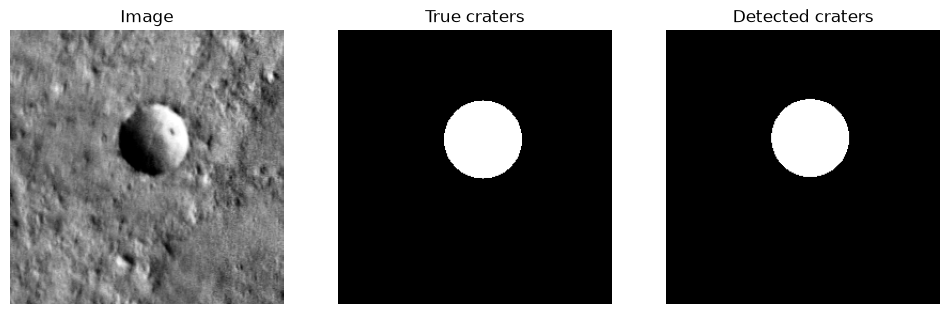

In [106]:
def load_image(image_id):
    image = Image.open(images_path / f"{image_id}.png").convert("RGB")
    return torch.tensor(np.array(image), dtype=torch.float32).permute(2, 0, 1) / 255.0


def detect_boxes(image_id):
    # Faster R-CNN gives (x1, y1, x2, y2); convert to (x, y, w, h) like the labels
    with torch.no_grad():
        out = model([load_image(image_id).to(device)])[0]
    keep = out["scores"] > cutoff
    return [[x1, y1, x2 - x1, y2 - y1] for x1, y1, x2, y2 in out["boxes"][keep].cpu().tolist()]


# test on one image
image_id = test_ids[0]
true_map = make_mask(data[image_id])
detected_map = make_mask(detect_boxes(image_id))

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(Image.open(images_path / f"{image_id}.png"), cmap="gray")
axes[0].set_title("Image")
axes[1].imshow(true_map, cmap="gray")
axes[1].set_title("True craters")
axes[2].imshow(detected_map, cmap="gray")
axes[2].set_title("Detected craters")
for ax in axes:
    ax.axis("off")
plt.show()

**A\* search.** The rover moves on the 256×256 grid, one cell at a time, in 8 directions 

A* finds the shortest route from start to goal that never enters a crater cell on the detected map.

The cost is calculated as 1 for straight moves and √2 for diagonal ones.

In [107]:
moves = [(-1, 0), (1, 0), (0, -1), (0, 1), (-1, -1), (-1, 1), (1, -1), (1, 1)]

def heuristic(a, b):
    # shortest possible distance with 8 moves and no obstacles
    dy, dx = abs(a[0] - b[0]), abs(a[1] - b[1])
    return max(dy, dx) + (2 ** 0.5 - 1) * min(dy, dx)


def astar(blocked, start, goal):
    # blocked: 256x256 array, 1 = no-go; start, goal: (row, col)
    open_list = [(heuristic(start, goal), 0.0, start)]
    came_from = {start: None}
    cost_so_far = {start: 0.0}

    while open_list:
        _, cost, cell = heapq.heappop(open_list)
        if cell == goal:
            path = []
            while cell is not None:
                path.append(cell)
                cell = came_from[cell]
            return path[::-1]
        if cost > cost_so_far[cell]:
            continue   # an older, worse entry for this cell

        for dy, dx in moves:
            ny, nx = cell[0] + dy, cell[1] + dx
            if not (0 <= ny < 256 and 0 <= nx < 256) or blocked[ny, nx]:
                continue
            new_cost = cost + (2 ** 0.5 if dy and dx else 1.0)
            if new_cost < cost_so_far.get((ny, nx), float("inf")):
                cost_so_far[(ny, nx)] = new_cost
                came_from[(ny, nx)] = cell
                heapq.heappush(open_list, (new_cost + heuristic((ny, nx), goal), new_cost, (ny, nx)))

    return None   # no path exists

**Tests:** A* on simple maps where we know the answer: an empty map, a wall to go around, and a wall with no way through.

In [108]:
# Test A* on simple maps where we know the answer
empty = np.zeros((256, 256), dtype=np.uint8)

# 1. no craters: straight line, 6 cells from (0, 0) to (0, 5)
path = astar(empty, (0, 0), (0, 5))
assert path == [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5)]

# 2. no craters, diagonal goal: 6 cells using only diagonal moves
assert len(astar(empty, (0, 0), (5, 5))) == 6

# 3. a wall from row 0 to row 9 at column 3: the path must go around it
wall = empty.copy()
wall[0:10, 3] = 1
path = astar(wall, (0, 0), (0, 6))
assert path[0] == (0, 0) and path[-1] == (0, 6)
assert all(wall[y, x] == 0 for y, x in path)   # never steps on the wall
assert len(path) > 7                            # longer than the straight line

# 4. a wall across the whole map: no path
full_wall = empty.copy()
full_wall[:, 3] = 1
assert astar(full_wall, (0, 0), (0, 6)) is None

print("A* tests passed")

A* tests passed


path length (cells): 256


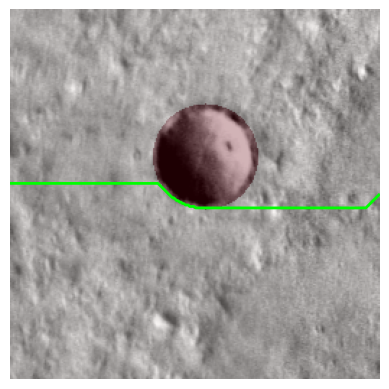

In [118]:
start, goal = (120, 0), (128, 255)
path = astar(detected_map, start, goal)

if path is None:
    print("no path")
else:
    print("path length (cells):", len(path))
    ys, xs = zip(*path)
    plt.imshow(Image.open(images_path / f"{image_id}.png"), cmap="gray")
    plt.imshow(true_map, cmap="Reds", alpha=0.3)
    plt.plot(xs, ys, color="lime", linewidth=2)
    plt.axis("off")
    plt.show()

# Simulations

We test the rover on the first 1,000 test images, with one route per image.

Each route has random start and goal points (on free cells) that are at least 150 cells apart.

For every crater entry, we check whether the detector missed it or not.

In [119]:
from torchvision.ops import box_iou

def path_length(path):
    return sum(2 ** 0.5 if (a[0] != b[0] and a[1] != b[1]) else 1.0 for a, b in zip(path, path[1:]))


def craters_entered(path, true_boxes):
    # indices of true craters whose circle contains at least one path cell
    ys = np.array([p[0] for p in path]) + 0.5
    xs = np.array([p[1] for p in path]) + 0.5
    entered = []
    for i, (x, y, w, h) in enumerate(true_boxes):
        cx, cy, r = x + w / 2, y + h / 2, max(w, h) / 2
        if np.any((xs - cx) ** 2 + (ys - cy) ** 2 <= r ** 2):
            entered.append(i)
    return entered


def was_detected(true_box, detected_boxes):
    # same rule as our scoring: a detected box with IoU >= 0.5
    if len(detected_boxes) == 0:
        return False
    to_xyxy = lambda b: [b[0], b[1], b[0] + b[2], b[1] + b[3]]
    ious = box_iou(torch.tensor([to_xyxy(true_box)], dtype=torch.float32),
                   torch.tensor([to_xyxy(b) for b in detected_boxes], dtype=torch.float32))
    return ious.max().item() >= 0.5


def pick_start_goal(free, rng, min_distance=150):
    cells = np.argwhere(free)
    for _ in range(200):
        a, b = cells[rng.integers(len(cells))], cells[rng.integers(len(cells))]
        if np.hypot(*(a - b)) >= min_distance:
            return tuple(int(v) for v in a), tuple(int(v) for v in b)
    return None


def simulate(image_id, rng):
    true_boxes = [b for b in data[image_id] if b[2] > 0 and b[3] > 0]
    detected_boxes = detect_boxes(image_id)
    true_map = make_mask(true_boxes)
    detected_map = make_mask(detected_boxes)

    pair = pick_start_goal((true_map == 0) & (detected_map == 0), rng)
    if pair is None:
        return None   # image too full of craters to place a far-apart start and goal
    start, goal = pair

    path = astar(detected_map, start, goal)
    if path is None:
        return {"image_id": image_id, "start": start, "goal": goal, "reached": False,
                "entered": 0, "entered_missed": 0, "length": None}

    entered = craters_entered(path, true_boxes)
    missed = [i for i in entered if not was_detected(true_boxes[i], detected_boxes)]
    return {"image_id": image_id, "start": start, "goal": goal, "reached": True,
            "entered": len(entered), "entered_missed": len(missed), "length": path_length(path)}


rng = np.random.default_rng(0)
print(simulate(test_ids[0], rng))

{'image_id': '053674', 'start': (75, 38), 'goal': (9, 204), 'reached': True, 'entered': 0, 'entered_missed': 0, 'length': 193.3380951166243}


In [120]:
from tqdm import tqdm

run_dir = Path("src-submit/rover-1/01-faster-rcnn")
run_dir.mkdir(parents=True, exist_ok=True)

rng = np.random.default_rng(0)
results = []
for image_id in tqdm(test_ids[:1000], mininterval=1.0):
    result = simulate(image_id, rng)
    if result is not None:
        results.append(result)

(run_dir / "results.json").write_text(json.dumps(results))
print(len(results), "runs")

100%|██████████| 1000/1000 [00:35<00:00, 28.46it/s]

1000 runs


In [121]:
reached = [r for r in results if r["reached"]]
entered_runs = [r for r in reached if r["entered"] > 0]
total_entered = sum(r["entered"] for r in reached)
total_missed = sum(r["entered_missed"] for r in reached)

print(f"runs: {len(results)}")
print(f"found a path: {len(reached) / len(results):.1%}")
print(f"runs that entered a true crater: {len(entered_runs) / len(reached):.1%}")
print(f"craters entered in total: {total_entered}")
print(f"  of those, missed by the detector: {total_missed} ({total_missed / max(total_entered, 1):.1%})")
print(f"average path length: {np.mean([r['length'] for r in reached]):.1f} cells")

runs: 1000
found a path: 100.0%
runs that entered a true crater: 9.3%
craters entered in total: 100
  of those, missed by the detector: 32 (32.0%)
average path length: 209.3 cells


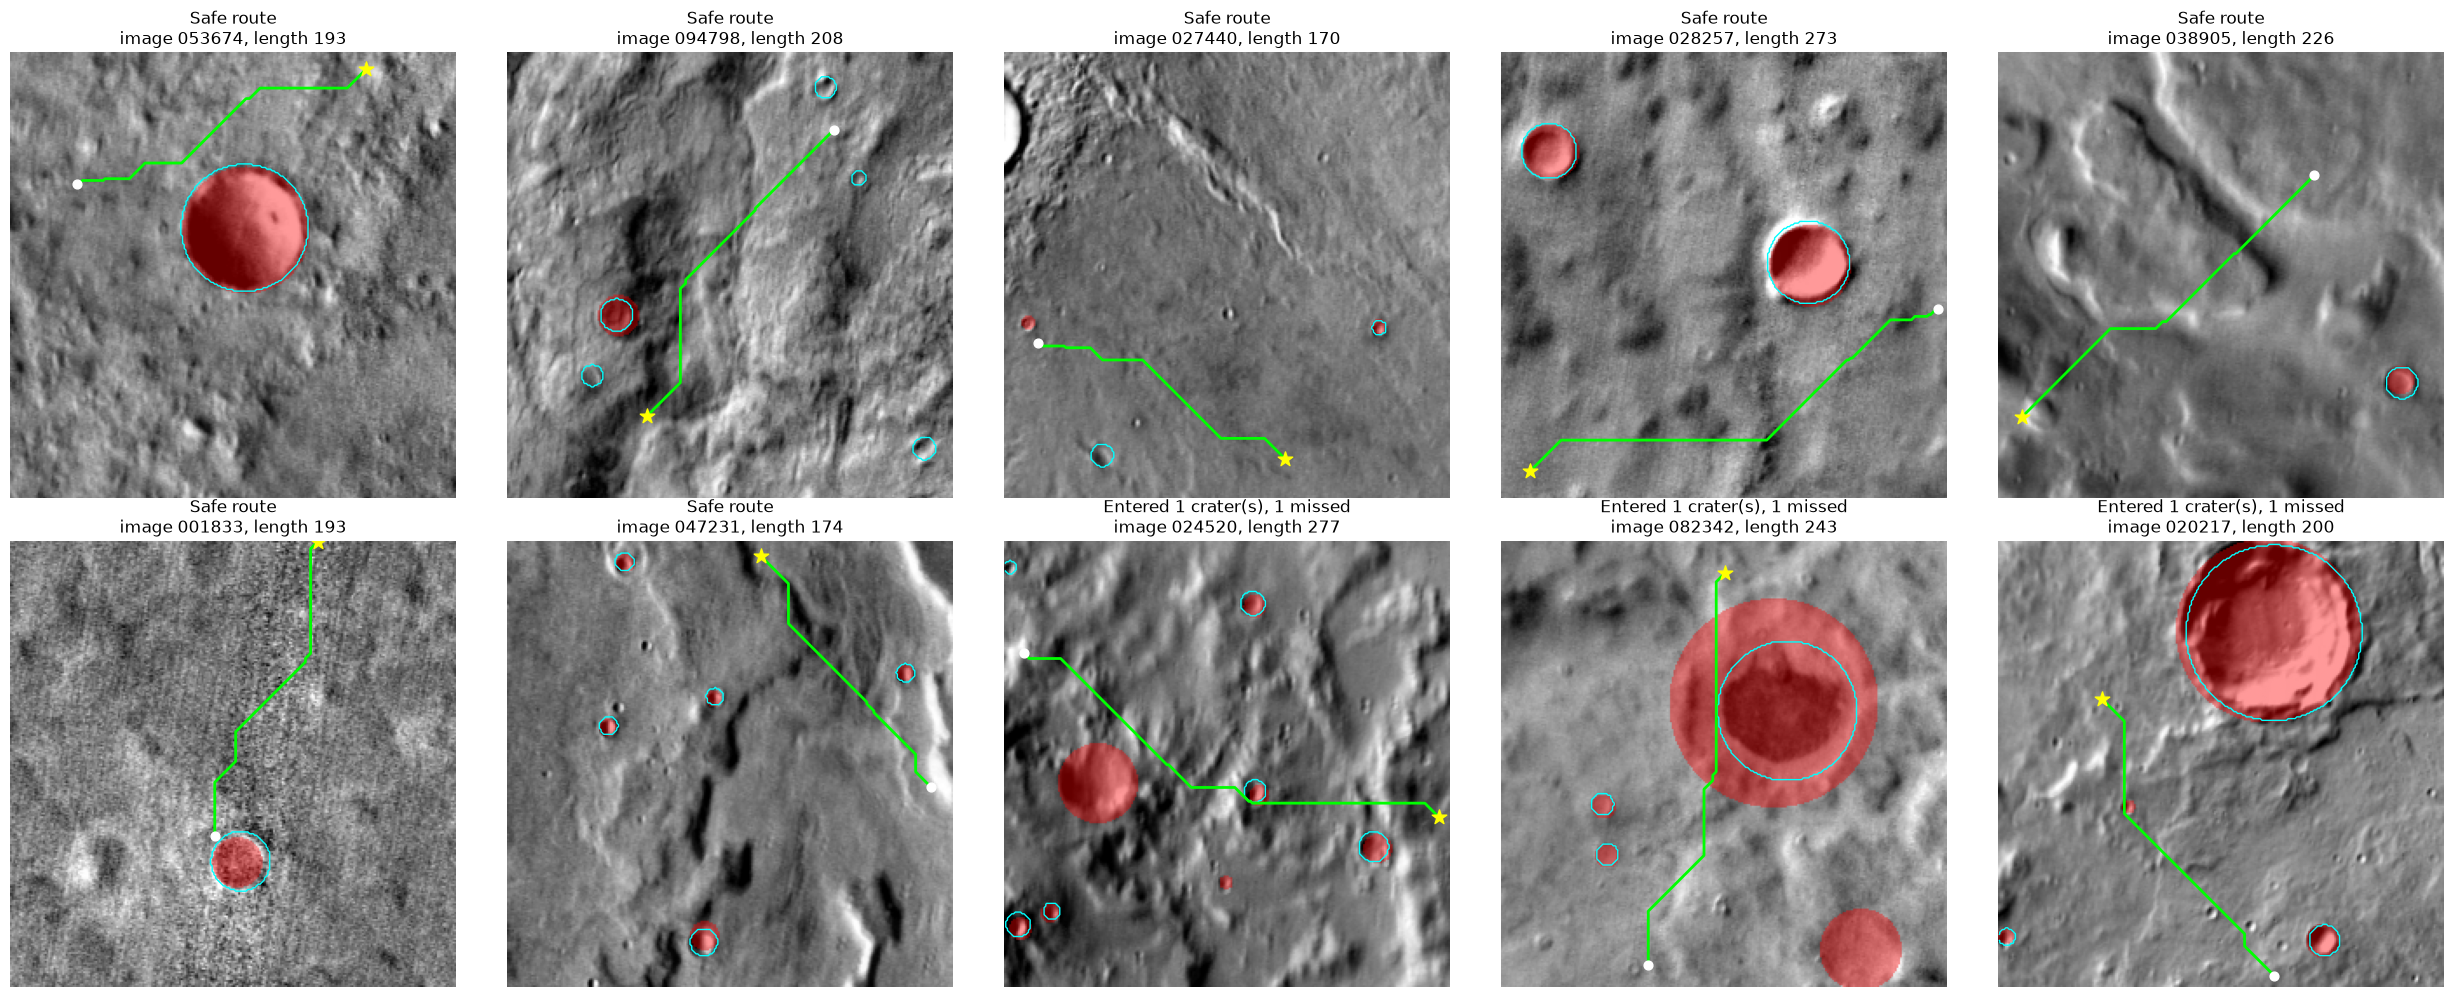

In [123]:
# pick 2 clean runs and 1 run that entered a crater (prefer one the detector missed)
clean = [r for r in results if r["reached"] and r["entered"] == 0][:7]   # was [:2]
bad = [r for r in results if r["entered_missed"] > 0] or [r for r in results if r["entered"] > 0]
chosen = clean + bad[:3]

fig, axes = plt.subplots(2, 5, figsize=(25, 10))

for ax, r in zip(axes.flat, chosen):
    image_id = r["image_id"]
    true_map = make_mask([b for b in data[image_id] if b[2] > 0 and b[3] > 0])
    detected_map = make_mask(detect_boxes(image_id))
    path = astar(detected_map, tuple(r["start"]), tuple(r["goal"]))
    ys, xs = zip(*path)

    ax.imshow(Image.open(images_path / f"{image_id}.png"), cmap="gray")
    ax.imshow(np.ma.masked_where(true_map == 0, true_map), cmap="autumn", alpha=0.4)   # true craters
    ax.contour(detected_map, levels=[0.5], colors="cyan", linewidths=1)               # detected craters
    ax.plot(xs, ys, color="lime", linewidth=2)                                        # route
    ax.scatter(xs[0], ys[0], color="white", s=40, zorder=3)                           # start
    ax.scatter(xs[-1], ys[-1], color="yellow", marker="*", s=120, zorder=3)           # goal

    title = "Safe route" if r["entered"] == 0 else f"Entered {r['entered']} crater(s), {r['entered_missed']} missed"
    ax.set_title(f"{title}\nimage {image_id}, length {r['length']:.0f}")
    ax.axis("off")

plt.tight_layout()
plt.savefig(run_dir / "routes.png", dpi=150, bbox_inches="tight")
plt.show()

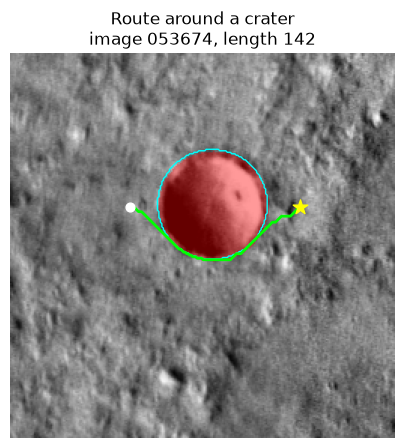

In [125]:
def route_around_crater(image_id, ax, gap=20):
    true_boxes = [b for b in data[image_id] if b[2] > 0 and b[3] > 0]
    true_map = make_mask(true_boxes)
    detected_map = make_mask(detect_boxes(image_id))

    # biggest true crater: its center and radius
    x, y, w, h = max(true_boxes, key=lambda b: max(b[2], b[3]))
    cx, cy, r = x + w / 2, y + h / 2, max(w, h) / 2

    # start left of it, goal right of it, same row, kept inside the image
    row = int(np.clip(cy, 0, 255))
    start = (row, int(np.clip(cx - r - gap, 0, 255)))
    goal = (row, int(np.clip(cx + r + gap, 0, 255)))

    path = astar(detected_map, start, goal)
    if path is None:
        print("no path for", image_id)
        return

    ys, xs = zip(*path)
    ax.imshow(Image.open(images_path / f"{image_id}.png"), cmap="gray")
    ax.imshow(np.ma.masked_where(true_map == 0, true_map), cmap="autumn", alpha=0.4)
    ax.contour(detected_map, levels=[0.5], colors="cyan", linewidths=1)
    ax.plot(xs, ys, color="lime", linewidth=2)
    ax.scatter(xs[0], ys[0], color="white", s=40, zorder=3)
    ax.scatter(xs[-1], ys[-1], color="yellow", marker="*", s=120, zorder=3)
    ax.set_title(f"Route around a crater\nimage {image_id}, length {path_length(path):.0f}")
    ax.axis("off")


fig, ax = plt.subplots(figsize=(5, 5))
route_around_crater("053674", ax)
plt.savefig(run_dir / "route_around_crater.png", dpi=150, bbox_inches="tight")
plt.show()

## Rover 1 Results:

- **Always reaches the goal:** A* found a path in all 1,000 runs.

- **Safe in most runs:** Only 9.3% of the runs entered a true crater (100 craters in total).

- **Most mistakes are not the detector's fault:** Only 32 of the 100 craters entered were missed by the detector. The other 68 were detected, but the rover still clipped their edge. A* finds the shortest path, so it drives right along the edge of the detected crater. This shows us precision of circle size and placement when detecting craters is as important asdetecting the craters themselves

- **Weakness and improvement:** As mentioned above, adding a little safety margin or making the circle bigger would probably avoid the most of the 68.

# Rover 2: A small network predicts which move to take (Behavior Cloning)

Rover 1 sees the whole crater map and plans ahead. Rover 2 is more like a real rover with a local view: at every step, it only sees a 15×15 window of the detected map around itself, plus the direction to the goal, and a small neural network decides the next move.

It learns with behavior cloning: the neural network is trained to copy the move that A* (on the true map) would take at each step. It trains like a classic classifier, with what the rover sees as the input and the move as the label.

- **Teacher:** A* on the true map
- **Student (Rover 2):** sees only the detected map (Faster R-CNN, cutoff 0.8), 15×15 cells around it

In [147]:
torch.manual_seed(0)
rng = np.random.default_rng(0)

run_dir = Path("src-submit/rover-2/01-basic-mlp")
run_dir.mkdir(parents=True, exist_ok=True)

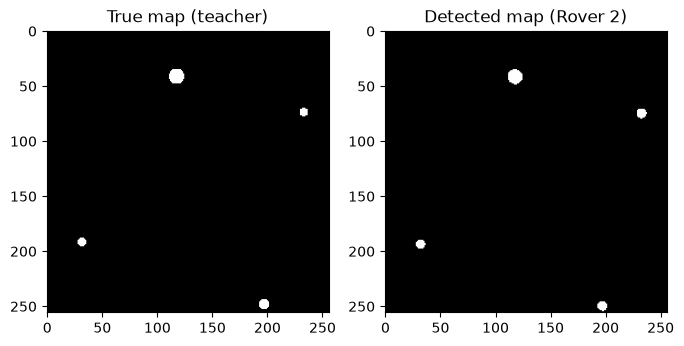

In [148]:
# load the trained Faster R-CNN
detector = fasterrcnn_resnet50_fpn(weights=None, weights_backbone=None, min_size=256)
in_features = detector.roi_heads.box_predictor.cls_score.in_features
detector.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes=2)
detector.load_state_dict(torch.load("src/faster-rcnn/01-baseline/model.pt", map_location=device))
detector.to(device)
detector.eval()


def detect_boxes(image_id):
    image = Image.open(images_path / f"{image_id}.png").convert("RGB")
    image = torch.tensor(np.array(image), dtype=torch.float32).permute(2, 0, 1) / 255.0
    with torch.no_grad():
        out = detector([image.to(device)])[0]
    keep = out["scores"] > 0.8   # best cutoff on validation
    return [[x1, y1, x2 - x1, y2 - y1] for x1, y1, x2, y2 in out["boxes"][keep].cpu().tolist()]


def get_maps(image_id):
    true_boxes = [b for b in data[image_id] if b[2] > 0 and b[3] > 0]
    return make_mask(true_boxes), make_mask(detect_boxes(image_id))


# quick check
true_map, detected_map = get_maps(train_ids[0])
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(true_map, cmap="gray")
axes[0].set_title("True map (teacher)")
axes[1].imshow(detected_map, cmap="gray")
axes[1].set_title("Detected map (Rover 2)")
plt.show()

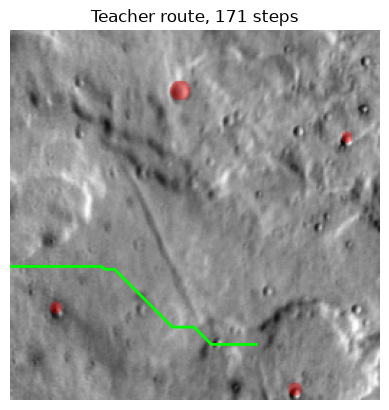

In [149]:
# check: the teacher drives one train route on the true map
image_id = train_ids[0]
true_map, detected_map = get_maps(image_id)
start, goal = pick_start_goal((true_map == 0) & (detected_map == 0), rng)
path = astar(true_map, start, goal)

ys, xs = zip(*path)
plt.imshow(Image.open(images_path / f"{image_id}.png"), cmap="gray")
plt.imshow(np.ma.masked_where(true_map == 0, true_map), cmap="autumn", alpha=0.4)
plt.plot(xs, ys, color="lime", linewidth=2)
plt.title(f"Teacher route, {len(path)} steps")
plt.axis("off")
plt.show()

**Rover 2's input** (227 numbers):
- the 15×15 window of the detected map centered on the rover (225 numbers, 1 = crater). Outside the image counts as crater, so the rover learns to stay on the map.
  
- the direction to the goal as a unit vector (2 numbers)

- the teacher drives 500 routes on train images and 100 on validation images.

(227,)
[-0.3027408 -0.9530729]


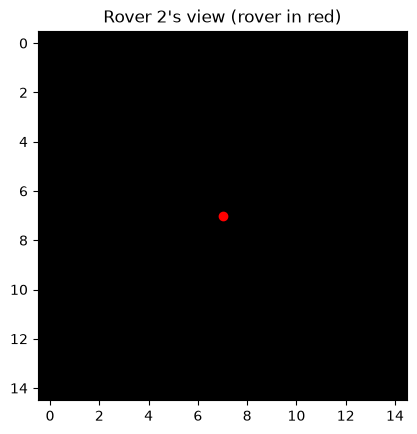

In [150]:
window = 15
half = window // 2   # 7 cells on each side of the rover


def observe(detected_map, cell, goal):
    # pad the map with 1s (crater) so the window never goes outside
    padded = np.pad(detected_map, half, constant_values=1)
    y, x = cell
    view = padded[y:y + window, x:x + window]   # centered on the rover

    dy, dx = goal[0] - y, goal[1] - x
    length = max((dy ** 2 + dx ** 2) ** 0.5, 1e-6)
    direction = [dy / length, dx / length]

    return np.concatenate([view.flatten(), direction]).astype(np.float32)


# check at the start of the route above
x = observe(detected_map, start, goal)
print(x.shape)          # (227,)
print(x[-2:])           # the direction to the goal
plt.imshow(x[:225].reshape(window, window), cmap="gray")
plt.scatter(half, half, color="red")
plt.title("Rover 2's view (rover in red)")
plt.show()

In [151]:
def make_data(ids, n_routes):
    X, Y = [], []
    for image_id in tqdm(ids[:n_routes], mininterval=1.0):
        true_map, detected_map = get_maps(image_id)
        pair = pick_start_goal((true_map == 0) & (detected_map == 0), rng)
        if pair is None:
            continue
        start, goal = pair
        path = astar(true_map, start, goal)   # the teacher knows every crater
        if path is None:
            continue

        for cell, next_cell in zip(path, path[1:]):
            move = (next_cell[0] - cell[0], next_cell[1] - cell[1])
            X.append(observe(detected_map, cell, goal))
            Y.append(moves.index(move))   # label: 0 to 7

    return torch.tensor(np.array(X)), torch.tensor(Y)


X_train, Y_train = make_data(train_ids, 500)
X_val, Y_val = make_data(val_ids, 100)

print(X_train.shape, Y_train.shape)
print(X_val.shape, Y_val.shape)
print("moves used by the teacher:", torch.bincount(Y_train, minlength=8).tolist())

100%|██████████| 100/100 [00:04<00:00, 23.87it/s]

torch.Size([88252, 227]) torch.Size([88252])
torch.Size([18409, 227]) torch.Size([18409])
moves used by the teacher: [13754, 11251, 10685, 12103, 9339, 9774, 9316, 12030]


**Model and training.**

- A small MLP: 227 → 128 (ReLU) → 8.
- One score per move. It is a classification problem, so the loss is `CrossEntropyLoss`.
- **Optimizer:** Adam, learning rate 0.001, constant (the standard default, kept simple).
- **10 epochs, batch size 256:** Each example is only 227 numbers and there are 88,000

In [152]:
from torch.utils.data import TensorDataset, DataLoader

model = nn.Sequential(
    nn.Linear(227, 128),
    nn.ReLU(),
    nn.Linear(128, 8),
).to(device)
print(sum(p.numel() for p in model.parameters()), "parameters")

train_loader = DataLoader(TensorDataset(X_train, Y_train), batch_size=256, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, Y_val), batch_size=256)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
epochs = 10

history = {"train_loss": [], "val_loss": [], "val_acc": []}
best_acc = 0

for epoch in range(epochs):
    # train
    model.train()
    total_loss = 0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        loss = loss_fn(model(x), y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    train_loss = total_loss / len(train_loader)

    # validate
    model.eval()
    total_loss, correct = 0, 0
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            total_loss += loss_fn(out, y).item()
            correct += (out.argmax(dim=1) == y).sum().item()
    val_loss = total_loss / len(val_loader)
    val_acc = correct / len(Y_val)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    if val_acc > best_acc:
        best_acc = val_acc
        torch.save(model.state_dict(), run_dir / "model.pt")

    print(f"epoch {epoch + 1}: train loss {train_loss:.4f}, val loss {val_loss:.4f}, val acc {val_acc:.3f}")

(run_dir / "history.json").write_text(json.dumps(history))

30216 parameters
epoch 1: train loss 1.0342, val loss 0.5963, val acc 0.753
epoch 2: train loss 0.5555, val loss 0.5687, val acc 0.747
epoch 3: train loss 0.5408, val loss 0.5676, val acc 0.750
epoch 4: train loss 0.5371, val loss 0.5645, val acc 0.751
epoch 5: train loss 0.5343, val loss 0.5596, val acc 0.753
epoch 6: train loss 0.5319, val loss 0.5631, val acc 0.749
epoch 7: train loss 0.5287, val loss 0.5604, val acc 0.750
epoch 8: train loss 0.5268, val loss 0.5572, val acc 0.749
epoch 9: train loss 0.5235, val loss 0.5673, val acc 0.748
epoch 10: train loss 0.5211, val loss 0.5608, val acc 0.749


642

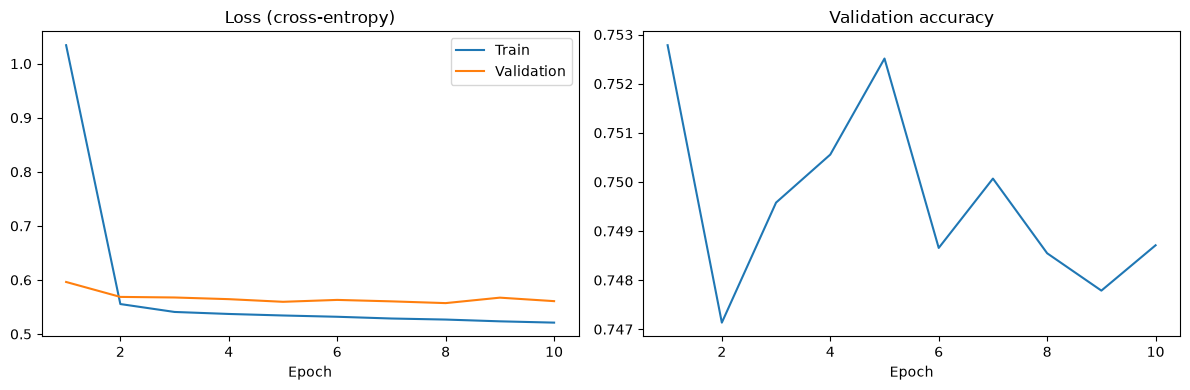

In [154]:
# training curves
epochs_range = range(1, len(history["train_loss"]) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(epochs_range, history["train_loss"], label="Train")
ax1.plot(epochs_range, history["val_loss"], label="Validation")
ax1.set_title("Loss (cross-entropy)")
ax1.set_xlabel("Epoch")
ax1.legend()

ax2.plot(epochs_range, history["val_acc"])
ax2.set_title("Validation accuracy")
ax2.set_xlabel("Epoch")

plt.tight_layout()
plt.savefig(run_dir / "curves.png", dpi=150, bbox_inches="tight")
plt.show()

# Simulations

- We test the rover on the first 1,000 test images, with one route per image. At each step, the rover looks at its windows and picks a move. It moves one cell at a time.

- We count the goal as reached when the rover is within 2 cells of it.

- We count the rover as lost when it uses 3x the shortest possible distance in steps without reaching the goal.

- Each route has random start and goal points (on free cells) that are at least 150 cells apart.

- We don't allow the rover to move outside the image, but an attempt to do so still counts as a step.

- For every crater entry, we check whether the detector missed it or not.

In [155]:
model.load_state_dict(torch.load(run_dir / "model.pt", map_location=device))
model.eval()


def drive(detected_map, start, goal):
    cell = start
    path = [cell]
    max_steps = int(3 * heuristic(start, goal))
    for _ in range(max_steps):
        if max(abs(cell[0] - goal[0]), abs(cell[1] - goal[1])) <= 2:
            return path, True   # reached the goal
        x = torch.tensor(observe(detected_map, cell, goal)).unsqueeze(0).to(device)
        with torch.no_grad():
            move = moves[model(x).argmax().item()]
        ny, nx = cell[0] + move[0], cell[1] + move[1]
        if 0 <= ny < 256 and 0 <= nx < 256:   # off the map: stay in place
            cell = (ny, nx)
        path.append(cell)
    return path, False   # ran out of steps


# Rover 1's exact test routes
rover1_results = json.loads(Path("src/rover-1/01-faster-rcnn/results.json").read_text())

results = []
for r in tqdm(rover1_results, mininterval=1.0):
    image_id, start, goal = r["image_id"], tuple(r["start"]), tuple(r["goal"])
    true_boxes = [b for b in data[image_id] if b[2] > 0 and b[3] > 0]
    detected_boxes = detect_boxes(image_id)
    detected_map = make_mask(detected_boxes)

    path, reached = drive(detected_map, start, goal)
    entered = craters_entered(path, true_boxes)
    missed = [i for i in entered if not was_detected(true_boxes[i], detected_boxes)]
    results.append({"image_id": image_id, "start": start, "goal": goal, "reached": reached,
                    "entered": len(entered), "entered_missed": len(missed), "length": path_length(path)})

(run_dir / "results.json").write_text(json.dumps(results))

100%|██████████| 1000/1000 [00:44<00:00, 22.34it/s]


144610

In [156]:
def summary(results):
    reached = [r for r in results if r["reached"]]
    total_entered = sum(r["entered"] for r in results)
    total_missed = sum(r["entered_missed"] for r in results)
    return {
        "reached goal": f"{len(reached) / len(results):.1%}",
        "runs that entered a crater": f"{sum(r['entered'] > 0 for r in results) / len(results):.1%}",
        "craters entered": total_entered,
        "  missed by detector": total_missed,
        "avg path length (reached runs)": f"{np.mean([r['length'] for r in reached]):.1f}" if reached else "-",
    }


for name, res in [("Rover 1 (A*, full map)", rover1_results), ("Rover 2 (MLP, 15x15 view)", results)]:
    print(name)
    for key, value in summary(res).items():
        print(f"  {key}: {value}")

Rover 1 (A*, full map)
  reached goal: 100.0%
  runs that entered a crater: 9.3%
  craters entered: 100
    missed by detector: 32
  avg path length (reached runs): 209.3
Rover 2 (MLP, 15x15 view)
  reached goal: 100.0%
  runs that entered a crater: 11.2%
  craters entered: 117
    missed by detector: 23
  avg path length (reached runs): 207.0


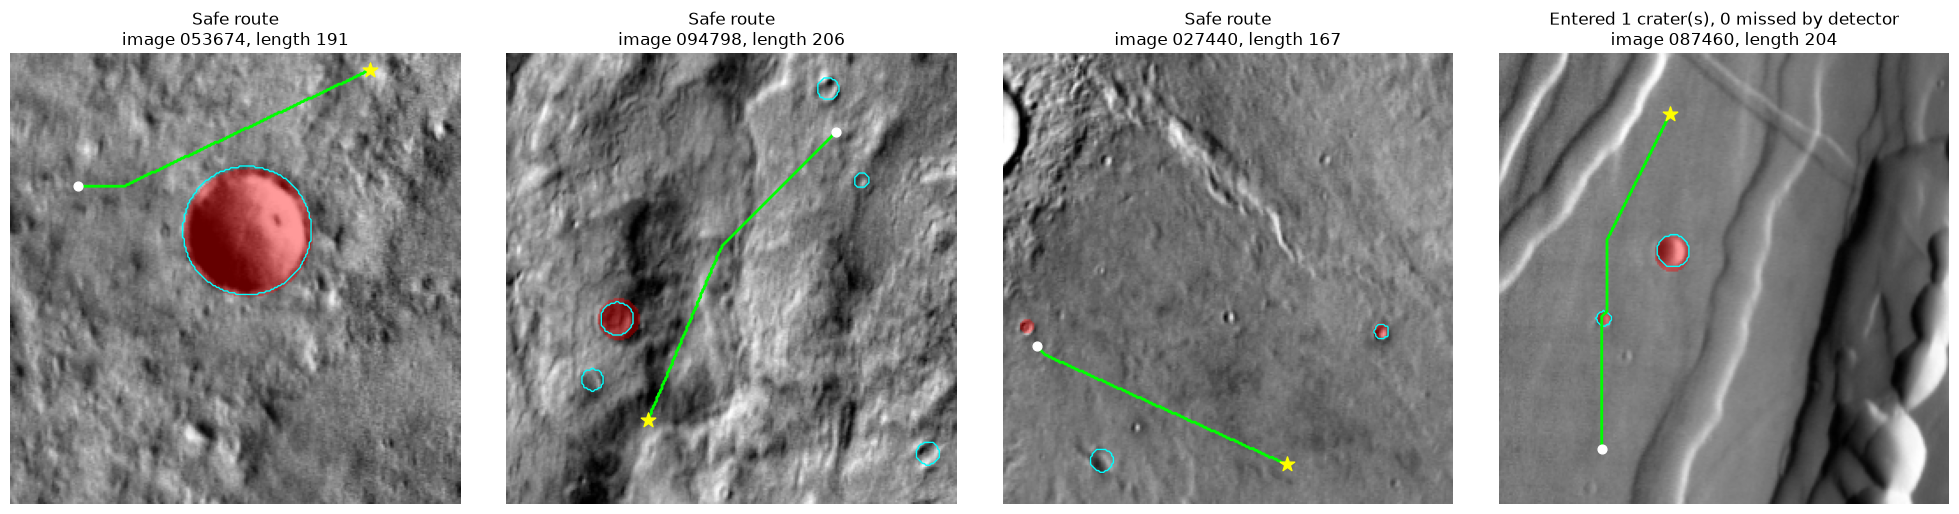

In [157]:
safe = [r for r in results if r["reached"] and r["entered"] == 0][:3]
own_mistake = [r for r in results if r["entered"] > r["entered_missed"]][:1]
lost = [r for r in results if not r["reached"]][:1]
chosen = safe + own_mistake + lost

fig, axes = plt.subplots(1, len(chosen), figsize=(5 * len(chosen), 5))

for ax, r in zip(axes, chosen):
    image_id = r["image_id"]
    true_map, detected_map = get_maps(image_id)
    path, reached = drive(detected_map, tuple(r["start"]), tuple(r["goal"]))
    ys, xs = zip(*path)

    ax.imshow(Image.open(images_path / f"{image_id}.png"), cmap="gray")
    ax.imshow(np.ma.masked_where(true_map == 0, true_map), cmap="autumn", alpha=0.4)   # true craters
    ax.contour(detected_map, levels=[0.5], colors="cyan", linewidths=1)               # detected craters
    ax.plot(xs, ys, color="lime", linewidth=2)                                        # Rover 2's route
    ax.scatter(xs[0], ys[0], color="white", s=40, zorder=3)                           # start
    ax.scatter(r["goal"][1], r["goal"][0], color="yellow", marker="*", s=120, zorder=3)   # goal

    if not reached:
        title = "Lost (ran out of steps)"
    elif r["entered"] == 0:
        title = "Safe route"
    else:
        title = f"Entered {r['entered']} crater(s), {r['entered_missed']} missed by detector"
    ax.set_title(f"{title}\nimage {image_id}, length {r['length']:.0f}")
    ax.axis("off")

plt.tight_layout()
plt.savefig(run_dir / "routes.png", dpi=150, bbox_inches="tight")
plt.show()

## Rover 2 Results:

- **Always reaches the goal:** Like Rover 1, it reached the goal in all 1,000 runs, with no lost runs. Like Rover 1, it reaches its goal all the time.

- **A little worse than Rover 1:** 11.2% of the runs entered a crater (117 craters), against 9.3% for Rover 1.

- **Weakness and improvement:** It was trained only on the teacher's perfect routes. Therefore, once it does a mistake, it does not know how to recover, it is not in its training data. An improvement would be training Rover 2 with a model that can learn from its own mistakes.

# Summary

We set out to determine whether deep learning could be useful for identifying craters on Mars's surface to help rovers plan their own routes. Our goal was to identify which kind of models detect craters the best, and whether a detector's mistakes matter for a rover.

**Results:**
- **Detection:** The fine-tuned Faster R-CNN performed the best ($F_1$ of 0.80), while the U-Net trained from scratch produced many false alarms ($F_1$ of 0.57), and the frozen DINOv3 missed most craters ($F_1$ of 0.21). Both baselines performed very poorly, since neither of them can see a whole crater at once.
- **Two ways of scoring:** Having two different ways to score our models was useful, since two models with the same pixel IoU score did not necessarily find craters equally well.
- **Rovers:** Both rovers reach the goal on every route. Rover 1 enters a crater in 9.3% of its routes and Rover 2 in 11.2%. Most crater entries came from detected craters with slightly wrong outlines, not from missed craters.

**Strengths:**
- All models use the same split, the epoch and cutoff are chosen on the validation set, and all reported numbers are on the test set.
- A full pipeline, from an orbital satellite image to a rover driving around the craters.

**Weaknesses:**
- Instead of enlarging the images to 800 × 800 to capture finer details, we used 256 × 256 images to keep training fast for Faster R-CNN.
- DINOv3 was kept frozen, which likely hurt it on small craters.
- Our labels are boxes turned into circles, so they only approximate the real crater shapes. In addition, many small craters were not labeled, some of which our detectors might have found but were counted as false detections, lowering their precision.
- The rover simulation is simple, and Rover 2 only copies A*, so it never learns from its own mistakes.

**Improvements:** Future work could include training the Faster R-CNN model on enlarged images, fine-tuning DINOv3, adding a small safety margin around detected craters, and training Rover 2 with a method that can learn from its own mistakes.